# SymPhase tutorial 4 — spin-space-group numbers and magnon chirality splitting

* **Spin space groups (SSG).** Collinear SSGs are in one-to-one correspondence with the black-and-white magnetic
  groups of type I, III and IV (replace every $[C_{2\perp}\|g]$ by $g\mathcal T$): 230 + 674 + 517 = **1421** groups.
  SymPhase labels a collinear SSG by the BNS number of that group, $\otimes\,^{\infty}m1$ (spin-only group).
* **Magnon chirality.** In a collinear magnet every magnon carries $\Delta S_z=\pm1$ (α / β). Without SOC the
  splitting $\Delta\omega(\mathbf q)=\omega_\beta-\omega_\alpha$ has the **same symmetry as the electronic spin splitting**:
  zero in PT- or $\tau$-connected antiferromagnets, d/g/i-wave in altermagnets.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

## 1. Spin-space-group labels of the examples

In [2]:
from symphase import analyze_tensors
for c in ["RuO2_Neel001_noSOC", "MnTe_altermagnet_INCAR", "Cr_bcc_AFM_INCAR", "Mn2Au_PT_AFM_INCAR",
          "bcc_Fe_m001", "fcc_Pt", "Mn3Sn_allin"]:
    sg = analyze_tensors(f"{EX}/vasp/{c}", tensors="charge")["spin_group"]
    print(f"{c:<24s} {sg['ssg']['label']}")

RuO2_Neel001_noSOC       P4_2'/mn'm (BNS 136.498, type III) ⊗ ∞m1


MnTe_altermagnet_INCAR   P6_3'/m'mc' (BNS 194.269, type III) ⊗ ∞m1


Cr_bcc_AFM_INCAR         P_Im-3m (BNS 221.97, type IV) ⊗ ∞m1


Mn2Au_PT_AFM_INCAR       I4/m'mm (BNS 139.533, type III) ⊗ ∞m1


bcc_Fe_m001              Im-3m (BNS 229.140, type I) ⊗ ∞m1
fcc_Pt                   G × O(3)  (spin fully decoupled)


Mn3Sn_allin              G = 24 lattice ops, spin-preserving subgroup 2 ops, spin point group of order 12 ⊗ m1


The black-and-white symbol and the spin Laue group are consistent: RuO₂ $P4_2'/mn'm$ ↔ $^24/^1m^2m^1m$ (primed = $^2$),
MnTe $P6_3'/m'mc'$ ↔ $^26/^2m^1m^2m$.

## 2. Symmetry classes of exchange bonds in RuO₂

Bonds related by any operation of the non-magnetic crystal share one $J$. In the altermagnet the two 6.35 Å bonds
along [110] and [1$\bar1$0] fall into **different** classes — the microscopic origin of chirality splitting.

In [3]:
import spglib, numpy as np
from symphase.tensors import read_poscar
from symphase.magnons import analyse, plot_bands, plot_split_map
p = read_poscar(f"{EX}/vasp/RuO2_Neel001_noSOC/POSCAR")
types = [0, 0, 1, 1, 1, 1]; symbols = ["Ru", "Ru", "O", "O", "O", "O"]
mags = np.array([[0, 0, 1.2], [0, 0, -1.2]] + [[0, 0, 0]] * 4)
ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], types))
res = analyse(p["lattice"], p["frac"], types, symbols, mags, ds.rotations, ds.translations, rmax=6.5)
for c in res["classes"]:
    print(f"J{c['cls']+1}: |d| = {c['L']:.3f} Å, {c['n_bonds']} bonds/cell, {c['spins']:<9s} e.g. {c['members'][:2]}")

J1: |d| = 3.110 Å, 2 bonds/cell, same      e.g. [(1, 1, [0, 0, 1]), (2, 2, [0, 0, 1])]
J2: |d| = 3.535 Å, 8 bonds/cell, opposite  e.g. [(1, 2, [-1, -1, -1]), (1, 2, [-1, -1, 0])]
J3: |d| = 4.490 Å, 4 bonds/cell, same      e.g. [(1, 1, [0, 1, 0]), (1, 1, [1, 0, 0])]
J4: |d| = 5.462 Å, 8 bonds/cell, same      e.g. [(1, 1, [0, 1, -1]), (1, 1, [0, 1, 1])]
J5: |d| = 5.643 Å, 8 bonds/cell, opposite  e.g. [(1, 2, [-1, -1, -2]), (1, 2, [-1, -1, 1])]
J6: |d| = 6.220 Å, 2 bonds/cell, same      e.g. [(1, 1, [0, 0, 2]), (2, 2, [0, 0, 2])]
J7: |d| = 6.350 Å, 2 bonds/cell, same      e.g. [(1, 1, [1, -1, 0]), (2, 2, [1, 1, 0])]
J8: |d| = 6.350 Å, 2 bonds/cell, same      e.g. [(1, 1, [1, 1, 0]), (2, 2, [1, -1, 0])]


## 3. Linear spin-wave theory

Illustrative exchange constants (meV, $J>0$ antiferromagnetic) with $J_7\neq J_8$ and a small easy-axis anisotropy:

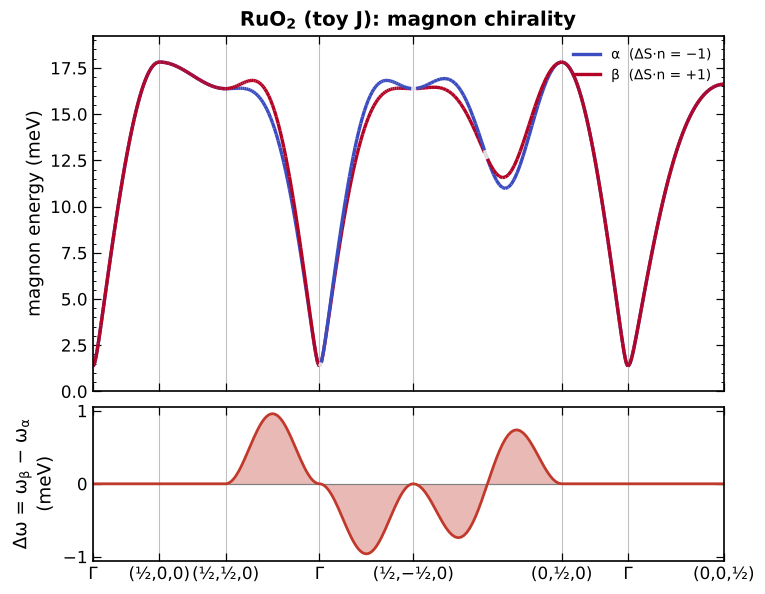

In [4]:
J = [-0.5, 3.0, -0.2, 0.0, 0.2, 0.0, -0.6, -0.2]
res = analyse(p["lattice"], p["frac"], types, symbols, mags, ds.rotations, ds.translations,
              J=J, K=0.05, rmax=6.5, n_per=50, nmap=41)
fig = plot_bands(res, title="RuO$_2$ (toy J): magnon chirality")

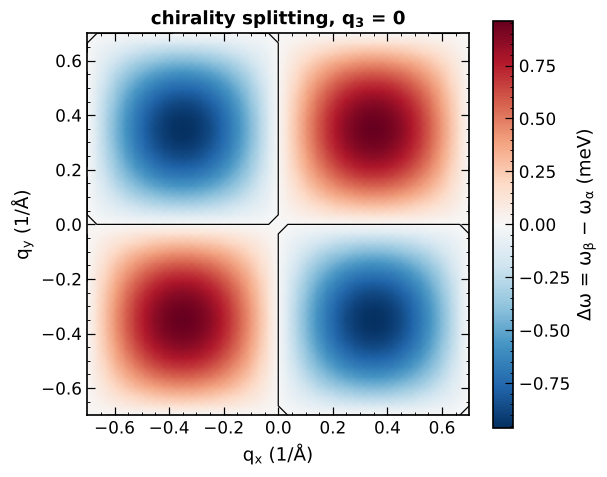

In [5]:
fig = plot_split_map(res)

Δω is odd under $q_x\to-q_x$ and $q_y\to-q_y$ and vanishes on both axes: **d-wave, $\Delta\omega\propto q_xq_y$**,
exactly the spin-group form $s_z\propto k_xk_y$. Setting $J_7=J_8$ removes the splitting:

In [6]:
res0 = analyse(p["lattice"], p["frac"], types, symbols, mags, ds.rotations, ds.translations,
               J=[-0.5, 3.0, -0.2, 0.0, 0.2, 0.0, -0.4, -0.4], K=0.05, rmax=6.5, n_per=20, nmap=11)
print("max |Δω| with J7 = J8:", np.nanmax(np.abs(res0["map_split"])), "meV")

max |Δω| with J7 = J8: 3.907985046680551e-14 meV


## 4. Command line

```bash
cd my_vasp_run/
symphase magnons --list-bonds --rmax 6.5          # bond classes
symphase magnons --J -0.5 3.0 -0.2 0 0.2 0 -0.6 -0.2 --K 0.05 --plot magnons.png
symphase magnons --exchange J.dat                 # i j n1 n2 n3 J(meV), e.g. from magex / TB2J
```
Moments come from OUTCAR or INCAR (`MAGMOM`); $S=|m|/2$ unless `--spin`. Validated against the analytic ferromagnet
and antiferromagnetic-chain dispersions (tests).